In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



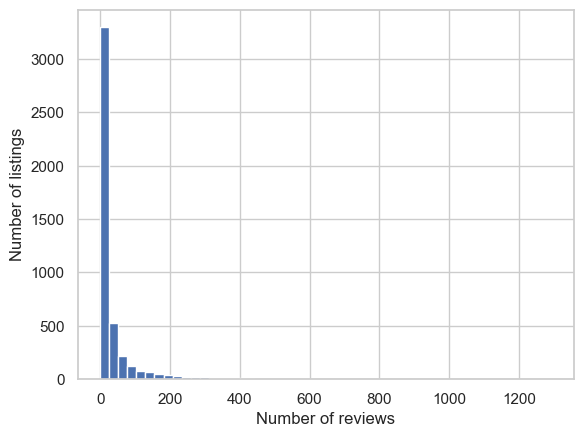

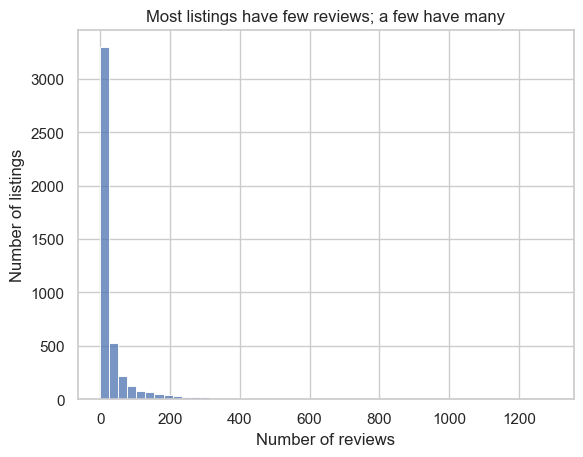

In [3]:
sns.set_theme(style="whitegrid")

listings = pd.read_csv("data/listings_clean.csv", parse_dates=["last_review"])

fig, ax = plt.subplots()
ax.hist(listings["number_of_reviews"].dropna(), bins=50)
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Number of listings")
plt.show()

sns.histplot(data=listings, x="number_of_reviews", bins=50)
plt.title("Most listings have few reviews; a few have many")
plt.xlabel("Number of reviews")
plt.ylabel("Number of listings")
plt.show()

Median: 9.0
Mean: 35.75404459991255
Upper fence: 69.5


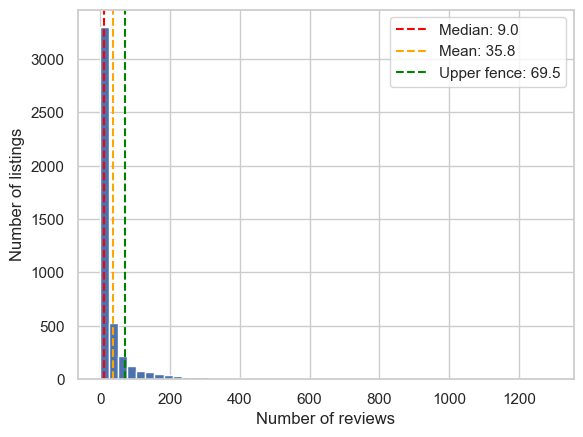

In [4]:
reviews = listings["number_of_reviews"].dropna()

median = reviews.median()
mean = reviews.mean()
q1 = reviews.quantile(0.25)
q3 = reviews.quantile(0.75)
upper_fence = q3 + 1.5 * (q3 - q1)

print("Median:", median)
print("Mean:", mean)
print("Upper fence:", upper_fence)

fig, ax = plt.subplots()
ax.hist(reviews, bins=50)
ax.axvline(median, color="red", linestyle="--", label=f"Median: {median:.1f}")
ax.axvline(mean, color="orange", linestyle="--", label=f"Mean: {mean:.1f}")
ax.axvline(upper_fence, color="green", linestyle="--",
           label=f"Upper fence: {upper_fence:.1f}")

ax.set_xlabel("Number of reviews")
ax.set_ylabel("Number of listings")
ax.legend()
plt.show()

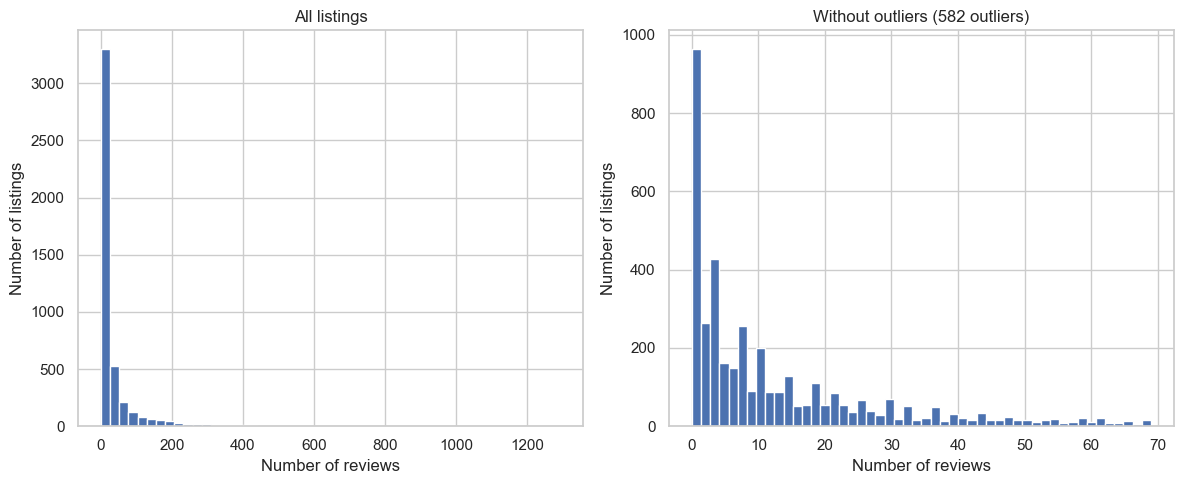

In [5]:
reviews = listings["number_of_reviews"]
q1 = reviews.quantile(0.25)
q3 = reviews.quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

listings["reviews_outlier"] = (
    (reviews < lower_fence) | (reviews > upper_fence)
)
outlier_count = listings["reviews_outlier"].sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(reviews.dropna(), bins=50)
axes[0].set_title("All listings")
axes[0].set_xlabel("Number of reviews")
axes[0].set_ylabel("Number of listings")

reviews_without_outliers = listings.loc[
    ~listings["reviews_outlier"], "number_of_reviews"
]
axes[1].hist(reviews_without_outliers.dropna(), bins=50)
axes[1].set_title(f"Without outliers ({outlier_count} outliers)")
axes[1].set_xlabel("Number of reviews")
axes[1].set_ylabel("Number of listings")

plt.tight_layout()
plt.show()

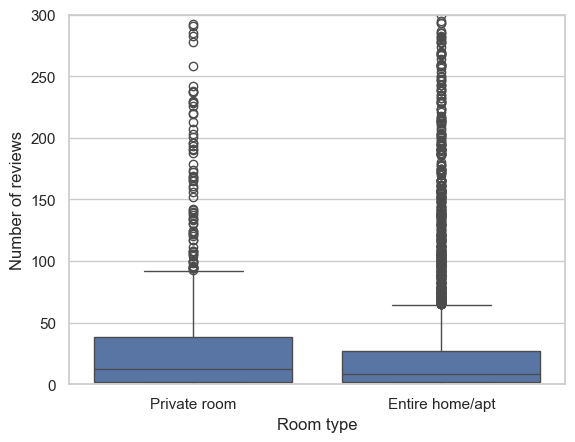

In [6]:
room_types = ["Entire home/apt", "Private room"]
two_room_types = listings[listings["room_type"].isin(room_types)]

fig, ax = plt.subplots()
sns.boxplot(data=two_room_types, x="room_type", y="number_of_reviews", ax=ax)
ax.set_ylim(0, 300)
ax.set_xlabel("Room type")
ax.set_ylabel("Number of reviews")
plt.show()

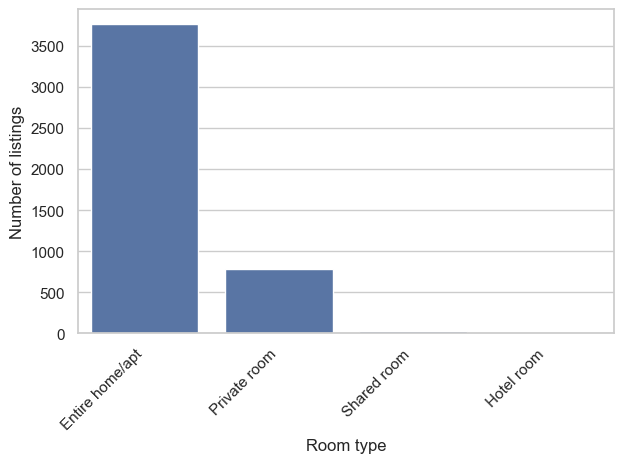

In [7]:
room_type_order = listings["room_type"].value_counts().index

fig, ax = plt.subplots()
sns.countplot(data=listings, x="room_type", order=room_type_order, ax=ax)
ax.set_xlabel("Room type")
ax.set_ylabel("Number of listings")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [8]:
neighbourhood_stats = (
    listings.groupby("neighbourhood_cleansed")
    .agg(
        median_reviews=("number_of_reviews", "median"),
        listing_count=("number_of_reviews", "size"),
    )
    .sort_values("median_reviews", ascending=False)
)

print(neighbourhood_stats)

                        median_reviews  listing_count
neighbourhood_cleansed                               
Södermalms                        17.0           1145
Kungsholmens                      12.0            420
Norrmalms                         10.0            469
Östermalms                         9.0            297
Älvsjö                             8.5            214
Hägersten-Liljeholmens             8.0            464
Skarpnäcks                         8.0            221
Spånga-Tensta                      7.0             89
Enskede-Årsta-Vantörs              7.0            445
Bromma                             5.0            281
Rinkeby-Tensta                     5.0            108
Farsta                             4.0            177
Hässelby-Vällingby                 4.0            148
Skärholmens                        3.0             96


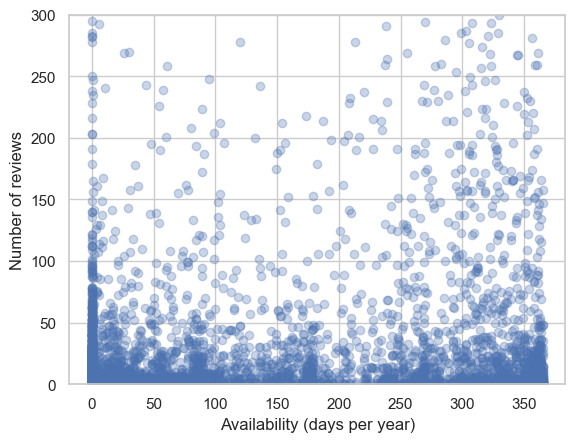

In [9]:
fig, ax = plt.subplots()
ax.scatter(
    listings["availability_365"],
    listings["number_of_reviews"],
    alpha=0.3,
)
ax.set_xlabel("Availability (days per year)")
ax.set_ylabel("Number of reviews")
ax.set_ylim(0, 300)
plt.show()

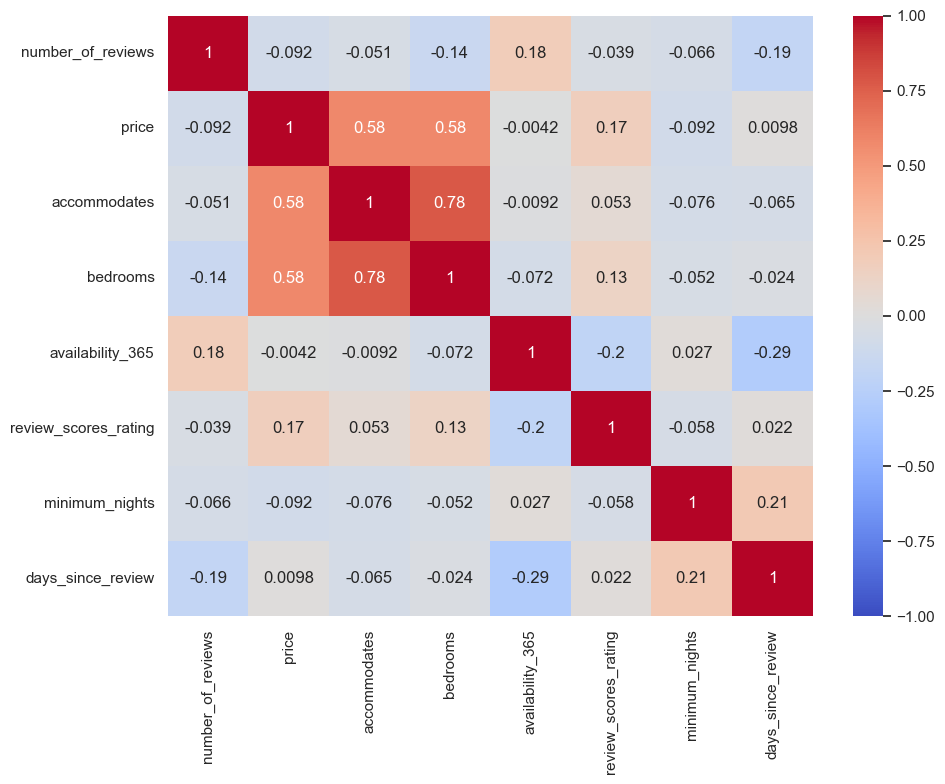

In [10]:
correlation_columns = [
    "number_of_reviews",
    "price",
    "accommodates",
    "bedrooms",
    "availability_365",
    "review_scores_rating",
    "minimum_nights",
    "days_since_review",
]

correlations = listings[correlation_columns].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    correlations,
    annot=True,
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
    ax=ax,
)
plt.tight_layout()
plt.show()

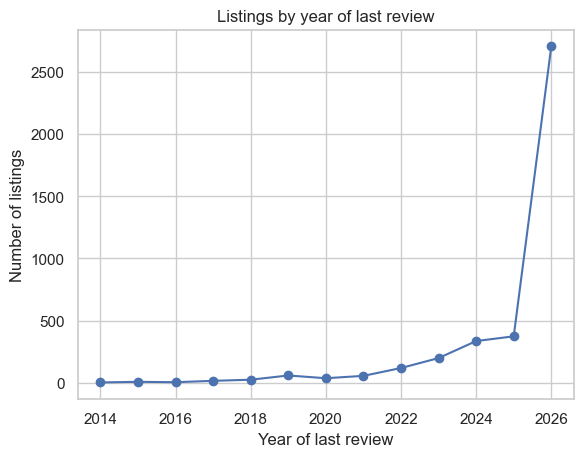

In [11]:
listings_per_year = listings.groupby(listings["last_review"].dt.year).size()

fig, ax = plt.subplots()
ax.plot(listings_per_year.index, listings_per_year.values, marker="o")
ax.set_xlabel("Year of last review")
ax.set_ylabel("Number of listings")
ax.set_title("Listings by year of last review")
plt.show()

room_type
Entire home/apt    4.92
Private room       4.89
Name: review_scores_rating, dtype: float64


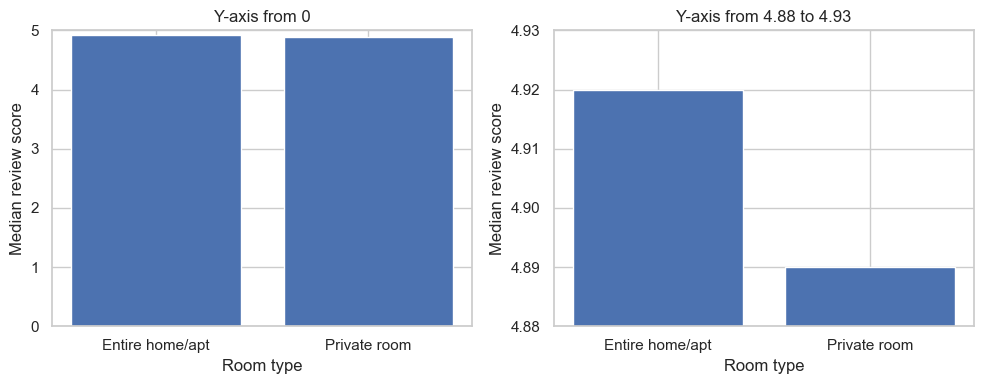

In [12]:
room_types = ["Entire home/apt", "Private room"]
two_room_types = listings[listings["room_type"].isin(room_types)]

median_ratings = (
    two_room_types.groupby("room_type")["review_scores_rating"]
    .median()
    .reindex(room_types)
)
print(median_ratings)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax in axes:
    ax.bar(median_ratings.index, median_ratings.values)
    ax.set_xlabel("Room type")
    ax.set_ylabel("Median review score")

axes[0].set_ylim(0, 5)
axes[0].set_title("Y-axis from 0")
axes[1].set_ylim(4.88, 4.93)
axes[1].set_title("Y-axis from 4.88 to 4.93")

plt.tight_layout()
plt.show()